# Study 9: prevalence by condition / test-feature-type match

Python remake of the `plot-induction-match` chunk in `study9_analysis.Rmd`
(saved there as `figs/prevalence_by_match.png`).

Steps follow the R code:
- exclusions: sound check == "bird", attention check == 100, AI == "No", task check correct
- ratings /100, then exact 0 -> 0.01 and 1 -> 0.99
- `match` = condition equals the test feature's type; `heterogeneous` = heterogeneous condition; otherwise `mismatch`
- mean of all ratings per group, with a 95% bootstrap CI over rows (as `mean_cl_boot` does)

Data: defaults to `data/study9_prereg.csv` (n = 388 after exclusions), which reproduces the existing figure
(match 59.1%, heterogeneous 49.7%, mismatch 53.2%). The Rmd currently points at `data/pilots/study9.csv`;
set `DATASET = 'pilot'` for that (n = 397).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import sys
from pathlib import Path

ROOT = Path('../..')
sys.path.insert(0, str(ROOT / 'model/per-feature-prevalence'))
import plot_style
plot_style.use_lexend()
DATASET = 'prereg'  # 'prereg' (matches the existing figure) or 'pilot'
CSV = {'pilot': ROOT / 'data/pilots/study9.csv',
       'prereg': ROOT / 'data/study9_prereg.csv'}[DATASET]

## Load, exclude, tidy

In [2]:
# Qualtrics export: row 0 = column names, rows 1-2 = question text / import ids
raw = pd.read_csv(CSV, skiprows=[1, 2], low_memory=False)
raw.columns = [c.removesuffix('_1') for c in raw.columns]

TEST_COLS = list(raw.loc[:, 'diet_can_eat_spicy':'phys_snore_sleep'].columns)

keep = ((raw['sound_check'] == 'bird')
        & (pd.to_numeric(raw['attn_check'], errors='coerce') == 100)
        & (raw['AI'] == 'No')
        & (raw['check_task'] == 'Answering questions about a fictional group of people'))
data = raw[keep].reset_index(drop=True)
data['participant'] = np.arange(len(data))
print(f'{DATASET}: collected {len(raw)}, kept {len(data)}, excluded {len(raw) - len(data)}')
print(data['condition'].value_counts().to_dict())

prereg: collected 419, kept 388, excluded 31
{'physical': 99, 'heterogeneous': 98, 'personality': 96, 'diet': 95}


In [3]:
TYPE = {'phys': 'physical', 'diet': 'diet', 'pers': 'personality'}

tidy = data.melt(id_vars=['participant', 'condition'], value_vars=TEST_COLS,
                 var_name='test_feature', value_name='prevalence')
tidy['prevalence'] = (pd.to_numeric(tidy['prevalence']) / 100).replace({0.0: 0.01, 1.0: 0.99})
tidy['test_feature_type'] = tidy['test_feature'].str.split('_').str[0].map(TYPE)
tidy['condition_test_match'] = np.select(
    [tidy['condition'] == 'heterogeneous', tidy['condition'] == tidy['test_feature_type']],
    ['heterogeneous', 'match'], default='mismatch')
tidy = tidy.dropna(subset=['prevalence'])
tidy.head()

,participant,condition,test_feature,prevalence,test_feature_type,condition_test_match
0,0,diet,diet_can_eat_spicy,0.37,diet,match
1,1,personality,diet_can_eat_spicy,0.31,diet,mismatch
2,2,physical,diet_can_eat_spicy,0.55,diet,mismatch
3,3,personality,diet_can_eat_spicy,0.50,diet,mismatch
4,4,personality,diet_can_eat_spicy,0.50,diet,mismatch


## Means and bootstrap CIs

In [4]:
ORDER = ['match', 'heterogeneous', 'mismatch']
rng = np.random.default_rng(0)

def boot_ci(x, n_boot=1000, level=0.95):
    x = np.asarray(x)
    means = rng.choice(x, size=(n_boot, len(x)), replace=True).mean(axis=1)
    return np.quantile(means, [(1 - level) / 2, (1 + level) / 2])

summary = pd.DataFrame([
    {'group': g, 'n': len(x), 'mean': x.mean(), **dict(zip(['lo', 'hi'], boot_ci(x)))}
    for g in ORDER for x in [tidy.loc[tidy['condition_test_match'] == g, 'prevalence'].to_numpy()]
]).set_index('group')
summary

,n,mean,lo,hi
group,,,,
match,1450,0.591062,0.575903,0.605596
heterogeneous,1470,0.497122,0.482339,0.511220
mismatch,2900,0.532352,0.521359,0.544388


## Plot

Everything you'd want to tweak is in the block at the top of the cell. Colors are
R's `purple`, `gray50`, `gray70`.

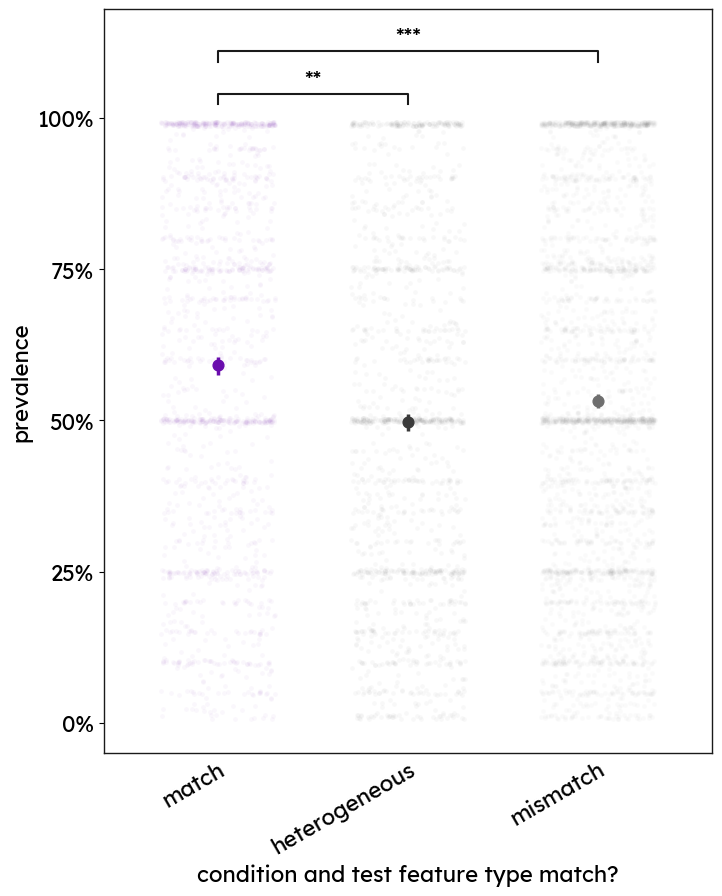

In [20]:
# ---- knobs ----
FIGSIZE = (7.5, 9.25)          # inches (ggsave used 5.75 x 5; matplotlib needs a bit more room at this font size)
YLIM = (-0.05, 1.05)           # ggplot pads the 0-1 limits a little (top is raised automatically for brackets)
YTICKS = [0, .25, .5, .75, 1]
JITTER_W = 0.3                 # half-width of the horizontal jitter
POINT_ALPHA = 0.03            # raw-data alpha (R used 0.007; try 0.02-0.05 to see the data)
TITLE = '' #'Prevalence by condition and test feature type match'
XLABEL = 'condition and test feature type match?'
YLABEL = 'prevalence'
FONT_SIZE = 16
XTICK_ROTATION = 30            # degrees; 0 for horizontal labels
COLORS = {'match': '#6A0DAD', 'heterogeneous': '#3A3A3A', 'mismatch': '#6E6E6E'}  # darkened for projector (R: purple, gray50, gray70)
INK = '0.1'                    # axes box, brackets
# significance brackets: (group_a, group_b, p) from the R pairwise emmeans contrasts on the
# beta GLMM (prereg; participant + test_feature random intercepts; Tukey-adjusted)
BRACKETS = [
    ('match', 'heterogeneous', 0.0010),     # z = 3.59
    ('match', 'mismatch',      0.0001),     # z = 8.63, reported as p < .0001
    ('heterogeneous', 'mismatch', 0.3819),  # z = -1.32
]
SHOW_NS = False                # draw non-significant pairs as 'n.s.'?
P_LABEL = 'stars'              # 'stars' or 'exact'
BRACKET_Y0 = 1.04              # height of the lowest bracket
BRACKET_STEP = 0.07            # vertical gap between stacked brackets
SAVE_TO = None                 # e.g. 'figs/prevalence_by_match.png'
# ---------------

def p_label(p):
    if P_LABEL == 'exact':
        return 'p < .001' if p < .001 else f'p = {p:.3f}'.replace('0.', '.')
    return '***' if p < .001 else '**' if p < .01 else '*' if p < .05 else 'n.s.'

def draw_brackets(ax, brackets):
    """Stacked brackets, shortest spans lowest. Returns the top y used."""
    pos = {g: i for i, g in enumerate(ORDER)}
    spans = sorted((sorted((pos[a], pos[b])) + [p] for a, b, p in brackets
                    if SHOW_NS or p < .05), key=lambda t: t[1] - t[0])
    y = BRACKET_Y0
    for x1, x2, p in spans:
        tip = BRACKET_STEP * 0.25
        ax.plot([x1, x1, x2, x2], [y - tip, y, y, y - tip], color=INK, lw=1.5, clip_on=False)
        ax.text((x1 + x2) / 2, y + 0.005, p_label(p), ha='center', va='bottom',
                fontsize=FONT_SIZE if P_LABEL == 'stars' else FONT_SIZE - 3)
        y += BRACKET_STEP
    return y

plt.rcParams.update({'font.size': FONT_SIZE})
fig, ax = plt.subplots(figsize=FIGSIZE)
jit = np.random.default_rng(1)

for i, g in enumerate(ORDER):
    y = tidy.loc[tidy['condition_test_match'] == g, 'prevalence'].to_numpy()
    x = i + jit.uniform(-JITTER_W, JITTER_W, len(y))
    y_j = y + jit.uniform(-0.004, 0.004, len(y))   # geom_jitter's default tiny vertical jitter
    ax.scatter(x, y_j, s=12, color=COLORS[g], alpha=POINT_ALPHA, linewidths=0, rasterized=True)
    s = summary.loc[g]
    ax.vlines(i, s['lo'], s['hi'], color=COLORS[g], lw=2.5, zorder=3)
    ax.scatter(i, s['mean'], s=60, color=COLORS[g], zorder=4)

ax.set_xticks(range(len(ORDER)), ORDER, rotation=XTICK_ROTATION,
              ha='right' if XTICK_ROTATION else 'center', rotation_mode='anchor')
ax.tick_params(axis='x', length=0)
ax.set_xlim(-0.6, len(ORDER) - 0.4)
y_top = draw_brackets(ax, BRACKETS)
ax.set_ylim(YLIM[0], max(YLIM[1], y_top))
ax.set_yticks(YTICKS)
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_xlabel(XLABEL)
ax.set_ylabel(YLABEL)
ax.set_title(TITLE, fontsize=FONT_SIZE + 2, loc='left')
for sp in ax.spines.values():   # theme_few: thin gray box
    sp.set_color(INK); sp.set_linewidth(1)

fig.tight_layout()
if SAVE_TO:
    fig.savefig(SAVE_TO, dpi=300, bbox_inches='tight')
plt.show()